# Benchmark: a spatial surface and a spatially confounded predictor

Data collected at locations usually carry a smooth spatial pattern that no
measured predictor explains, and a predictor that itself varies over space
can absorb part of it. This study simulates 1,000 rows at random locations in
the unit square with

$$
y = 0.8\sin 2\pi x_1 + 0.5x_2 + g(\text{lon}, \text{lat}) + \varepsilon,
\qquad \varepsilon \sim N(0, 0.5^2),
$$

where the surface $g$ is two Gaussian bumps and a gradient, $x_1$ follows a
spatial pattern of its own plus noise, and $x_3$ is irrelevant. The training
rows avoid the upper-right square where lon and lat are both above 0.6, 16% of the area.
Predictions are scored on 3,000 new locations over the whole square
(interpolation), drawn from the same region as the training rows, and 3,000
in the empty square (a gap).

mboostrs fits `bbs` terms for the predictors and `bspatial(lon, lat)`, a
tensor-product P-spline surface; `gam_refit` refits that model by REML, and a
model without the spatial term shows what ignoring space costs. The
competitors are mgcv (a thin-plate spline `s(lon, lat)` with `k=60` basis
functions), GPBoost (tree
boosting for the predictors plus a Gaussian process with a Matérn covariance
on the coordinates), EBM with its pair terms, and XGBoost and LightGBM with the
coordinates as features.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | predictions at new locations inside and outside the sampled region, and the effect of a predictor that varies over space |
| **Observed response** | simulated continuous response with a spatial surface |
| **Estimand** | RMSE against the noise-free signal at new locations in the sampled region and in the empty square; the error of the partial dependence of $x_1$ against the true centred curve; the error of the recovered surface on a 20 x 20 grid of sampled locations |
| **Units** | response units |
| **Sampling unit** | one location; 1,000 training and 2 x 3,000 test locations per seed |
| **Dependence** | rows share the spatial surface; the noise is independent |
| **Split / resampling unit** | fresh locations from the same design, and a region the training rows avoid |
| **Tuning** | mboostrs: `tune_mstop` (5-fold CV); mgcv: REML with a 60-dimensional surface basis; GPBoost: 4-fold CV of the number of boosting rounds; trees: early stopping on a 20% validation split; EBM: defaults |
| **Uncertainty** | mean and standard error over 8 seeds |
| **Claim type** | methodological |
:::

In [1]:
import json
from pathlib import Path

import altair as alt
import polars as pl

bench = json.loads(Path("bench_spatial.json").read_text())
failed = [r for r in bench["results"] if "error" in r]
spatial = pl.from_dicts([r for r in bench["results"] if "error" not in r],
                        infer_schema_length=None, strict=False)
COLUMNS = ["rmse_interpolation", "rmse_gap", "x1_effect_rmse", "surface_rmse", "seconds"]
table = (spatial.group_by("method")
         .agg([pl.col(c).mean().alias(c) for c in COLUMNS]
              + [(pl.col("rmse_interpolation").std() / pl.len().sqrt()).alias("se")])
         .sort("rmse_interpolation"))


def value(method, column):
    return float(table.filter(pl.col("method") == method)[column][0])


from bench_tables import table as annotated

In [2]:
display(annotated(
    table.select("method", "rmse_interpolation", "se", "rmse_gap", "x1_effect_rmse",
                 "surface_rmse", "seconds"),
    title="A spatial surface: prediction inside and outside the sampled region",
    subtitle="Mean over 8 seeds; 1,000 training locations avoiding the upper-right square",
    spanners={"Prediction RMSE ↓": ["rmse_interpolation", "se", "rmse_gap"],
              "Effect error ↓": ["x1_effect_rmse", "surface_rmse"]},
    labels={"rmse_interpolation": "sampled region", "rmse_gap": "gap",
            "x1_effect_rmse": "x1 curve", "surface_rmse": "surface", "seconds": "s"},
    better={"rmse_interpolation": "min", "rmse_gap": "min", "x1_effect_rmse": "min",
            "surface_rmse": "min"},
    formats={"seconds": 1},
    notes=["Prediction RMSE: root mean squared difference between the prediction and the "
           "noise-free signal at 3,000 new locations in the sampled region, and at 3,000 in "
           "the empty square (the gap), in response units; the noise sd is 0.5. se: "
           "standard error of the sampled-region RMSE over seeds.",
           "x1 curve: RMSE of the partial dependence of the spatially patterned predictor "
           "x1 against its true centred curve. surface: RMSE of the recovered spatial "
           "surface on a 20 × 20 grid of sampled locations. s: mean seconds per fit including tuning. Bold: best in the "
           "column. Source: bench_spatial.json, written by benches/bench_spatial.py."]))
f"{spatial.height} fits; {len(failed)} failed"

GT(_tbl_data=shape: (8, 7)
┌────────────────┬───────────────┬──────────┬──────────┬───────────────┬──────────────┬────────────┐
│ method         ┆ rmse_interpol ┆ se       ┆ rmse_gap ┆ x1_effect_rms ┆ surface_rmse ┆ seconds    │
│ ---            ┆ ation         ┆ ---      ┆ ---      ┆ e             ┆ ---          ┆ ---        │
│ str            ┆ ---           ┆ f64      ┆ f64      ┆ ---           ┆ f64          ┆ f64        │
│                ┆ f64           ┆          ┆          ┆ f64           ┆              ┆            │
╞════════════════╪═══════════════╪══════════╪══════════╪═══════════════╪══════════════╪════════════╡
│ mgcv           ┆ 0.103488      ┆ 0.0045   ┆ 0.121436 ┆ 0.045034      ┆ 0.088988     ┆ 5.950169   │
│ mboostrs +     ┆ 0.107506      ┆ 0.003943 ┆ 0.171547 ┆ 0.045134      ┆ 0.093859     ┆ 43.672553  │
│ REML refit     ┆               ┆          ┆          ┆               ┆              ┆            │
│ mboostrs       ┆ 0.11507       ┆ 0.003267 ┆ 0.171927 ┆ 0.035074      ┆ 0.098089     ┆ 41.386329  │
│ GPBoost        ┆ 0.161105      ┆ 0.004208 ┆ 0.275744 ┆ 0.109681      ┆ 0.092623     ┆ 118.979562 │
│ EBM            ┆ 0.165688      ┆ 0.002753 ┆ 0.192196 ┆ 0.052793      ┆ 0.14485      ┆ 13.706569  │
│ LightGBM       ┆ 0.197327      ┆ 0.006563 ┆ 0.206458 ┆ 0.087466      ┆ 0.15633      ┆ 1.515715   │
│ XGBoost        ┆ 0.206723      ┆ 0.004797 ┆ 0.219996 ┆ 0.087011      ┆ 0.158109     ┆ 1.82264    │
│ mboostrs       ┆ 0.346648      ┆ 0.002149 ┆ 0.388515 ┆ 0.113492      ┆ 0.360594     ┆ 0.57397    │
│ without        ┆               ┆          ┆          ┆               ┆              ┆            │
│ spatial term   ┆               ┆          ┆          ┆               ┆              ┆            │
└────────────────┴───────────────┴──────────┴──────────┴───────────────┴──────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10e144a70>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='rmse_interpolation', type=<ColInfoTypeEnum.default: 1>, column_label='sampled region', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='rmse_gap', type=<ColInfoTypeEnum.default: 1>, column_label='gap', column_align='right', column_width=None), ColInfo(var='x1_effect_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='x1 curve', column_align='right', column_width=None), ColInfo(var='surface_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='surface', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e3705f0>, _spanners=Spanners([SpannerInfo(spanner_id='Prediction RMSE ↓', spanner_level=0, spanner_label='Prediction RMSE ↓', spanner_units=None, spanner_pattern=None, vars=['rmse_interpolation', 'se', 'rmse_gap'], built=None), SpannerInfo(spanner_id='Effect error ↓', spanner_level=0, spanner_label='Effect error ↓', spanner_units=None, spanner_pattern=None, vars=['x1_effect_rmse', 'surface_rmse'], built=None)]), _heading=Heading(title='A spatial surface: prediction inside and outside the sampled region', subtitle='Mean over 8 seeds; 1,000 training locations avoiding the upper-right square', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10dd2cfe0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10dd1acc0>, _source_notes=['Prediction RMSE: root mean squared difference between the prediction and the noise-free signal at 3,000 new locations in the sampled region, and at 3,000 in the empty square (the gap), in response units; the noise sd is 0.5. se: standard error of the sampled-region RMSE over seeds.', 'x1 curve: RMSE of the partial dependence of the spatially pattern

'64 fits; 0 failed'

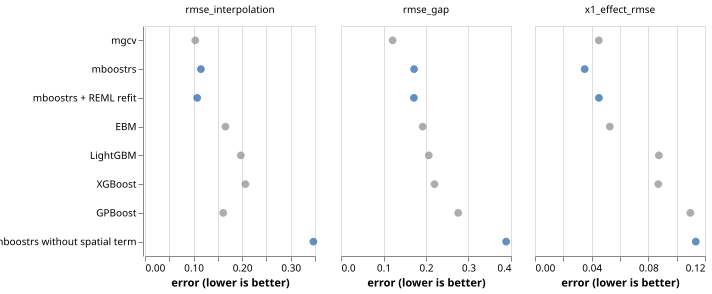

In [3]:
long = table.unpivot(index="method", on=["rmse_interpolation", "rmse_gap", "x1_effect_rmse"],
                     variable_name="measure", value_name="error").with_columns(
    pl.col("method").str.starts_with("mboostrs").alias("mboostrs"))
display(alt.Chart(long).mark_point(filled=True, size=60).encode(
    x=alt.X("error:Q", title="error (lower is better)"),
    y=alt.Y("method:N", sort=alt.EncodingSortField("error", op="mean"), title=None),
    color=alt.Color("mboostrs:N", legend=None, scale=alt.Scale(range=["#8a8a8a", "#1f5fa8"])),
    column=alt.Column("measure:N", title=None,
                      sort=["rmse_interpolation", "rmse_gap", "x1_effect_rmse"]),
).resolve_scale(x="independent").properties(width=170, height=230))

## Results

At new locations inside the sampled region mgcv is most accurate
({eval}`round(value("mgcv", "rmse_interpolation"), 3)`), followed by the
mboostrs REML refit ({eval}`round(value("mboostrs + REML refit", "rmse_interpolation"), 3)`)
and the boosted mboostrs model
({eval}`round(value("mboostrs", "rmse_interpolation"), 3)`); EBM, GPBoost and
the tree libraries are between
{eval}`round(min(value(m, "rmse_interpolation") for m in ("EBM", "GPBoost", "XGBoost", "LightGBM")), 3)`
and
{eval}`round(max(value(m, "rmse_interpolation") for m in ("EBM", "GPBoost", "XGBoost", "LightGBM")), 3)`.
Leaving the spatial term out multiplies the error by
{eval}`round(value("mboostrs without spatial term", "rmse_interpolation") / value("mboostrs", "rmse_interpolation"), 1)`
({eval}`round(value("mboostrs without spatial term", "rmse_interpolation"), 3)`).

The effect of $x_1$, which varies over space, is recovered best by the
boosted mboostrs model (error
{eval}`round(value("mboostrs", "x1_effect_rmse"), 3)`, against
{eval}`round(value("mgcv", "x1_effect_rmse"), 3)` for mgcv and
{eval}`round(value("GPBoost", "x1_effect_rmse"), 3)` for GPBoost). Without the
spatial term the $x_1$ curve absorbs part of the surface and its error rises
to {eval}`round(value("mboostrs without spatial term", "x1_effect_rmse"), 3)`.
GPBoost's Gaussian process recovers the surface about as well as mgcv
(surface error {eval}`round(value("GPBoost", "surface_rmse"), 3)` against
{eval}`round(value("mgcv", "surface_rmse"), 3)`), while its $x_1$ effect has the
largest error of the methods with a spatial term.

In the square with no training rows every method extrapolates. mgcv's
thin-plate surface does so most smoothly
({eval}`round(value("mgcv", "rmse_gap"), 3)`); the tensor P-spline surfaces of
mboostrs, boosted and refitted, have errors of
{eval}`round(value("mboostrs", "rmse_gap"), 3)` and
{eval}`round(value("mboostrs + REML refit", "rmse_gap"), 3)`, and GPBoost the largest of the
methods that model space ({eval}`round(value("GPBoost", "rmse_gap"), 3)`).

mboostrs is also slower than mgcv here:
{eval}`round(value("mboostrs", "seconds"), 1)` seconds per fit with tuning
against {eval}`round(value("mgcv", "seconds"), 1)`, measured on one thread with nine
fits running at once, so the times are comparable with each other but longer
than a fit run alone. Cross-validating the step
count refits the model once per fold and per doubling of the step grid, and
each fit calibrates the smoothing parameter of the 576-column spatial basis
from its `df`.

## Package fixes

* **`gam_refit` did not accept `bspatial` or `%X%` terms.** It now refits a
  tensor-product surface with one REML smoothing parameter per margin, as
  mgcv's `te()` does, and reports both in `smoothing`.
* **Calibrating a large basis was slow.** Converting `df` to a smoothing
  parameter computed an inverse Cholesky factor with an element-wise loop;
  a blocked triangular solve cut the spatial term's setup from 0.29 to 0.17
  seconds, and tuning this model, run alone on one thread, from 14.6 to 11.0
  seconds.
* **The spatial learner's preparation was the largest remaining piece of
  the setup cost** (#284). Centering the 576-column tensor basis ran a full
  spectral decomposition of its penalty, and calibrating `df` ran a Cholesky
  inverse, two dense products and an SVD. Both now run through the two
  marginal 24×24 eigenproblems instead of one 576×576 problem: centering keeps
  the penalty's rescaled eigen-coordinates, and calibration costs a single
  eigenproblem. Preparing this study's spatial term fell from 88 to 50
  milliseconds per fit, and a 10,000-row fit's preparation from 225 to 45,
  measured on one M2 core. The study's wall time barely moves, because its
  boosting iterations dominate it. The timings in the Results table were
  measured with several fits running at once, so they are comparable within
  the table only.


## Spatial basis size

The main comparison fits 20 inner knots per margin in `bspatial`, or 576
unreduced tensor columns. To measure what this choice costs, the same eight
training and test draws were fitted again with either 12 or 20 inner knots
per margin. Both used `df=6` and the same five cross-validation folds within
each seed. The saved check is separate from `bench_spatial.json`, so its
single-run times are compared only within the two basis settings.


In [4]:
basis_check = json.loads(Path("bench_spatial_basis_refresh.json").read_text())
basis_runs = pl.DataFrame(basis_check["results"])
basis_summary = (basis_runs.group_by("knots")
    .agg(pl.len().alias("fits"),
         pl.col("rmse_interpolation").mean(),
         pl.col("rmse_gap").mean(),
         pl.col("seconds").mean())
    .sort("knots"))

def basis_value(knots, column):
    return float(basis_summary.filter(pl.col("knots") == knots)[column][0])

# The paired rows hold the same generated data and folds at both sizes.
display(annotated(
    basis_summary.with_columns(pl.format("{} knots", pl.col("knots")).alias("basis"))
    .drop("knots").select("basis", "fits", "rmse_interpolation", "rmse_gap", "seconds"),
    title="bspatial basis size: 12 against 20 knots per coordinate",
    subtitle="The same generated data and folds at both sizes",
    stub="basis", stubhead="Basis",
    labels={"rmse_interpolation": "sampled region ↓", "rmse_gap": "gap ↓", "seconds": "s"},
    better={"rmse_interpolation": "min", "rmse_gap": "min"}, formats={"seconds": 1},
    notes=["Prediction RMSE against the noise-free signal, as in the first table. fits: "
           "paired fits at each size. Bold: the lower error. Source: "
           "bench_spatial_basis_refresh.json."]))


GT(_tbl_data=shape: (2, 5)
┌──────────┬──────┬────────────────────┬──────────┬───────────┐
│ basis    ┆ fits ┆ rmse_interpolation ┆ rmse_gap ┆ seconds   │
│ ---      ┆ ---  ┆ ---                ┆ ---      ┆ ---       │
│ str      ┆ u32  ┆ f64                ┆ f64      ┆ f64       │
╞══════════╪══════╪════════════════════╪══════════╪═══════════╡
│ 12 knots ┆ 8    ┆ 0.133768           ┆ 0.185464 ┆ 6.419033  │
│ 20 knots ┆ 8    ┆ 0.128798           ┆ 0.171927 ┆ 35.389527 │
└──────────┴──────┴────────────────────┴──────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10e172d50>, _boxhead=Boxhead([ColInfo(var='basis', type=<ColInfoTypeEnum.stub: 2>, column_label='basis', column_align='left', column_width=None), ColInfo(var='fits', type=<ColInfoTypeEnum.default: 1>, column_label='fits', column_align='right', column_width=None), ColInfo(var='rmse_interpolation', type=<ColInfoTypeEnum.default: 1>, column_label='sampled region ↓', column_align='right', column_width=None), ColInfo(var='rmse_gap', type=<ColInfoTypeEnum.default: 1>, column_label='gap ↓', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x112529700>, _spanners=Spanners([]), _heading=Heading(title='bspatial basis size: 12 against 20 knots per coordinate', subtitle='The same generated data and folds at both sizes', preheader=None), _stubhead='Basis', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10d8bb9e0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10e370050>, _source_notes=['Prediction RMSE against the noise-free signal, as in the first table. fits: paired fits at each size. Bold: the lower error. Source: bench_spatial_basis_refresh.json.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10e3702c0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10e197b00>, <great_tables._gt_data.FormatInfo object at 0x1125297c0>, <great_tables._gt_data.FormatInfo object at 0x112528cb0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x112529250>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_s

The 12-knot basis takes {eval}`round(basis_value(12, "seconds"), 1)`
seconds on average, versus {eval}`round(basis_value(20, "seconds"), 1)` for
20 knots. Its interpolation RMSE is
{eval}`round(basis_value(12, "rmse_interpolation"), 3)` versus
{eval}`round(basis_value(20, "rmse_interpolation"), 3)`, and its gap RMSE is
{eval}`round(basis_value(12, "rmse_gap"), 3)` versus
{eval}`round(basis_value(20, "rmse_gap"), 3)`. The smaller basis saves time
but loses accuracy on these draws, especially in the region without
training locations. The default is therefore retained; a faster fit can be
requested explicitly with `bspatial(lon, lat, knots=12, df=6)` when this
tradeoff is acceptable.


## Summary

| Question | Leader | mboostrs |
|---|---|---|
| Prediction at new locations | mgcv | second (REML refit) and third (boosted) |
| Effect of a spatially patterned predictor | mboostrs | best |
| Prediction in an unsampled region | mgcv | behind mgcv, ahead of GPBoost |
| Time | tree libraries, mgcv | slower than mgcv |

## Limitations

One surface shape and one sample size; a rougher surface or a denser sample
would favour the Gaussian process. mboostrs used the default 20 inner knots
per margin for the spatial term, which creates 24 basis columns per margin
and 576 tensor columns before centering; mgcv used `k=60` thin-plate basis
functions. The fit-time comparison therefore includes a substantial basis-size
difference, as well as implementation cost. The results are in
`docs/book/cases/bench_spatial.json`, produced by `benches/bench_spatial.py`.